In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# CartPole-v1/200: analytic six-qubit ring majority versus parity

This notebook repeats the matched graph-IQP CartPole comparison with **six qubits**, so deterministic majority contains every Pauli-(Z) locality. It preserves the earlier protocol:

- the six-qubit periodic ring and the same state-conditioned `IQPAnsatz`;
- depths (L=1,2,3);
- 500 training episodes capped at 200 steps;
- ten matched seeds ((3,7,11,23,37,41,43,47,53,59));
- Adam/REINFORCE settings, state normalization, entropy coefficient, baseline, and gradient clipping from the five-qubit sweep;
- identical initial trainable tensors for parity and majority within every `(depth, seed)` pair;
- exact statevector probabilities and exact automatic-differentiation gradients (`shots=None`).

The environment and categorical action selection remain stochastic; “analytic” refers to circuit evaluation and differentiation, not deterministic actions.

For a measured bitstring (z\in\{0,1\}^6), deterministic ties map to action zero:
\[
a_{\rm maj}(z)=\begin{cases}0,&|z|\le 3,\\1,&|z|\ge4.\end{cases}
\]
The parity comparator uses (a_{\rm par}(z)=|z|\bmod 2). Because there are two actions, the “modulo” step is the identity after producing the single majority bit.

In [1]:
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import sys
import time
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

# Independent jobs use one numerical thread each.
for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",
             "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from qasp import IQPAnsatz, NeuralEmbedding, CircuitBuilder, REINFORCE
from qasp.rl.model import create_model

ROOT = Path(".")
RESULTS_DIR = ROOT / "tests" / "results" / "cartpole_6q_even_majority_vs_parity"
RUNS_DIR = RESULTS_DIR / "runs"
INITIAL_DIR = RESULTS_DIR / "initial_states"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, INITIAL_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

N_QUBITS = 6
N_ACTIONS = 2
DEPTHS = (1, 2, 3)
SEEDS = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
N_EPISODES = 500
MAX_STEPS = 200
FINAL_WINDOW = 50
SMOOTHING_WINDOW = 20
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100
N_JOBS = min(4, os.cpu_count() or 1)
RING_EDGES = tuple((i, (i + 1) % N_QUBITS) for i in range(N_QUBITS))

TRAINING = {
    "gamma": 0.99,
    "lr": 3e-2,
    "batch_episodes": 5,
    "logits": False,
    "normalize_mode": "clip",
    "normalize_returns": True,
    "entropy_coef": 5e-3,
    "baseline_type": "ema",
    "baseline_momentum": 0.05,
    "max_grad_norm": 1.0,
}

EPISODES_CSV = RESULTS_DIR / "episode_returns.csv"
RUN_SUMMARY_CSV = RESULTS_DIR / "run_summary.csv"
STATISTICS_CSV = RESULTS_DIR / "statistical_summary.csv"
METADATA_JSON = RESULTS_DIR / "metadata.json"
INITIALIZATION_JSON = RESULTS_DIR / "matched_initialization_audit.json"
FIGURE_PDF = FIGURES_DIR / "cartpole_6q_even_majority_vs_parity.pdf"
FIGURE_PNG = FIGURES_DIR / "cartpole_6q_even_majority_vs_parity.png"

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 10,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

print("Results:", RESULTS_DIR)
print("Parallel workers:", N_JOBS)
print("Ring edges:", RING_EDGES)

Results: ./tests/results/cartpole_6q_even_majority_vs_parity
Parallel workers: 4
Ring edges: ((0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0))


## Exact six-qubit decoder and Pauli decomposition

Let (M_6=\Pi_0-\Pi_1), with (M_6(z)=+1) for (|z|\le3) and (-1) otherwise. Writing (Z_S=\prod_{i\in S}Z_i),
\[
M_6=\frac{5}{16}I
+\frac{5}{16}\sum_{|S|=1}Z_S
-\frac{1}{16}\sum_{|S|=2}Z_S
-\frac{1}{16}\sum_{|S|=3}Z_S
+\frac{1}{16}\sum_{|S|=4}Z_S
+\frac{1}{16}\sum_{|S|=5}Z_S
-\frac{5}{16}Z_1Z_2Z_3Z_4Z_5Z_6.
\]
Thus (Pi_0=(I+M_6)/2). The tie rule assigns 42 basis states to action zero and 22 to action one, whereas parity assigns 32 states to each action. The cell below independently verifies the full Walsh spectrum and these bin counts.

In [2]:
def fwht(values):
    out = np.asarray(values, dtype=np.float64).copy()
    width = 1
    while width < len(out):
        blocks = out.reshape(-1, 2 * width)
        left, right = blocks[:, :width].copy(), blocks[:, width:].copy()
        blocks[:, :width], blocks[:, width:] = left + right, left - right
        width *= 2
    return out / len(out)


states = np.arange(1 << N_QUBITS, dtype=np.int64)
bits = ((states[:, None] >> np.arange(N_QUBITS - 1, -1, -1)) & 1)
weights = bits.sum(axis=1)
majority_action = (weights > N_QUBITS // 2).astype(np.int64)
parity_action = weights % 2
majority_signed = np.where(majority_action == 0, 1.0, -1.0)
coefficients = fwht(majority_signed)
subset_weights = weights
expected = {0: 5/16, 1: 5/16, 2: -1/16, 3: -1/16,
            4: 1/16, 5: 1/16, 6: -5/16}
decomposition_rows = []
for locality in range(N_QUBITS + 1):
    sector = coefficients[subset_weights == locality]
    decomposition_rows.append({
        "locality": locality,
        "multiplicity": math.comb(N_QUBITS, locality),
        "numerical_coefficient": float(sector.mean()),
        "theory_coefficient": expected[locality],
        "max_within_sector_deviation": float(np.max(np.abs(sector - sector.mean()))),
    })
decomposition = pd.DataFrame(decomposition_rows)
np.testing.assert_allclose(
    decomposition.numerical_coefficient,
    decomposition.theory_coefficient,
    rtol=0, atol=1e-15,
)
assert np.bincount(majority_action, minlength=2).tolist() == [42, 22]
assert np.bincount(parity_action, minlength=2).tolist() == [32, 32]
display(decomposition)
print("Majority basis bins:", np.bincount(majority_action, minlength=2))
print("Parity basis bins:", np.bincount(parity_action, minlength=2))

,locality,multiplicity,numerical_coefficient,theory_coefficient,max_within_sector_deviation
0,0,1,0.3125,0.3125,0.0
1,1,6,0.3125,0.3125,0.0
2,2,15,-0.0625,-0.0625,0.0
3,3,20,-0.0625,-0.0625,0.0
4,4,15,0.0625,0.0625,0.0
5,5,6,0.0625,0.0625,0.0
6,6,1,-0.3125,-0.3125,0.0


Majority basis bins: [42 22]
Parity basis bins: [32 32]


## Matched QASP circuit and analytic statevector implementation

The production model below is a batched PyTorch statevector realization of the same QASP `IQPAnsatz`. It obtains its initial tensors from QASP's live initializer, then applies the same state-conditioned (Z), trainable (Z), ring-(ZZ), and Hadamard programs. This avoids SparseHamiltonian overhead while retaining exact probabilities and exact gradients. Before training, both policy outputs and parameter gradients are checked against native QASP (`lightning.qubit`, `shots=None`, adjoint differentiation) at all three depths.

In [3]:
def parameter_hash(mapping):
    payload = b"".join(
        value.detach().cpu().contiguous().numpy().tobytes()
        for name, value in sorted(mapping.items())
    )
    return hashlib.sha256(payload).hexdigest()


def qasp_config(depth, policy):
    common = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": int(depth),
            "imprimitive_pattern": [list(edge) for edge in RING_EDGES],
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": N_ACTIONS,
        "init": "normal_0_1",
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(range(N_QUBITS)),
        "parity_cnot_decomposition": False,
        "enable_mpi": False,
    }
    if policy == "parity":
        return {**common, "policy": "parity-like", "training_method": "expectation"}
    if policy == "majority":
        return {
            **common, "policy": "majority-modulo",
            "training_method": "sparse_projectors",
            "majority_blocks": [list(range(N_QUBITS))],
        }
    raise ValueError(policy)


def create_native_qasp(depth, policy, seed):
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    return create_model("PQCBorn", qasp_config(depth, policy), n_qubits=N_QUBITS)


# Generate one authoritative initialization per matched (depth, seed) pair.
initialization_audit = []
for depth in DEPTHS:
    for seed in SEEDS:
        path = INITIAL_DIR / f"L{depth}__seed_{seed}.pt"
        if not path.exists():
            native = create_native_qasp(depth, "parity", seed)
            state = {name: value.detach().cpu().clone()
                     for name, value in native.qlayer.state_dict().items()}
            torch.save(state, path)
            del native
        state = torch.load(path, map_location="cpu", weights_only=True)
        initialization_audit.append({
            "depth": depth, "seed": seed,
            "parameter_count": int(sum(value.numel() for value in state.values())),
            "trainable_parameter_sha256": parameter_hash(state),
            "state_path": str(path),
        })
INITIALIZATION_JSON.write_text(json.dumps(initialization_audit, indent=2) + "\n")
display(pd.DataFrame(initialization_audit))

,depth,seed,parameter_count,trainable_parameter_sha256,state_path
0,1,3,36,90f84cc986049013f4a31e3233f6ebe5f9460996a6737b...,./tests/result...
1,1,7,36,44ac4e1621f848560c3783ff5962cce7b34026c8e03a76...,./tests/result...
2,1,11,36,9c30bd89da9b51414240c8aa0916681070eb9223fc7b54...,./tests/result...
3,1,23,36,308ef88ca281c03aadcb8dc9848e14427262993ea5ae76...,./tests/result...
4,1,37,36,545fffe893cd96febfec93ef4fe4f29a4d139ec6442781...,./tests/result...
5,1,41,36,a84a2530447aff022d6f5188593a9dcb68efb3feb0db37...,./tests/result...
6,1,43,36,bcc7a4ed060c5705320b2150804eb0489999a052b84800...,./tests/result...
7,1,47,36,b4bdc070351978f87974ca64364338b8f0623ef5b36088...,./tests/result...
8,1,53,36,319aecddbd87f34e8e073081acb213673cd78da4aa8c63...,./tests/result...
9,1,59,36,0a247f704a8dd5829dbacf3413e7ae761a9c251be187da...,./tests/result...


In [4]:
class ExactSixQubitRingPolicy(torch.nn.Module):
    '''Exact differentiable statevector for the validated QASP ring IQP circuit.'''
    def __init__(self, depth, policy, initial_state):
        super().__init__()
        self.depth = int(depth)
        self.policy = policy
        self.input_scaling_params = torch.nn.Parameter(
            initial_state["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial_state["params"].clone())
        self.forward_calls = 0

        basis = torch.arange(1 << N_QUBITS, dtype=torch.long)
        shifts = torch.arange(N_QUBITS - 1, -1, -1, dtype=torch.long)
        basis_bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        self.register_buffer("z_signs", (1.0 - 2.0 * basis_bits).T)
        self.register_buffer("zz_signs", torch.stack([
            self.z_signs[left] * self.z_signs[right]
            for left, right in RING_EDGES
        ]))
        hamming = basis_bits.sum(dim=1)
        if policy == "parity":
            pi0 = (hamming.remainder(2) == 0).to(torch.float32)
        elif policy == "majority":
            pi0 = (hamming <= N_QUBITS // 2).to(torch.float32)
        else:
            raise ValueError(policy)
        self.register_buffer("pi0_basis", pi0)

    @staticmethod
    def _hadamards(state):
        result = state
        width, dimension = 1, state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left, right = blocks[..., 0, :], blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, observations):
        observations = torch.as_tensor(observations, dtype=torch.float32)
        dimension = 1 << N_QUBITS
        batch_shape = observations.shape[:-1]
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        scaling = self.input_scaling_params.reshape(self.depth, N_QUBITS, 4)
        block = N_QUBITS + len(RING_EDGES)
        for layer in range(self.depth):
            encoded = torch.einsum("...f,qf->...q", observations, scaling[layer])
            start = layer * block
            local = self.params[start:start + N_QUBITS]
            edges = self.params[start + N_QUBITS:start + block]
            phase = torch.einsum("...q,qd->...d", encoded, self.z_signs)
            phase = phase + torch.einsum("q,qd->d", local, self.z_signs)
            phase = phase + torch.einsum("e,ed->d", edges, self.zz_signs)
            state = state * torch.exp(-0.5j * phase)
            state = self._hadamards(state)
        return state.abs().square().real

    def forward(self, observations):
        self.forward_calls += 1
        basis = self.exact_basis_probs(observations)
        p0 = torch.einsum("...d,d->...", basis, self.pi0_basis)
        probabilities = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        eps = torch.finfo(probabilities.dtype).eps
        return probabilities / probabilities.sum(dim=-1, keepdim=True).clamp_min(eps)


def load_exact_policy(depth, policy, seed):
    initial = torch.load(
        INITIAL_DIR / f"L{depth}__seed_{seed}.pt",
        map_location="cpu", weights_only=True,
    )
    return ExactSixQubitRingPolicy(depth, policy, initial)


# Bitwise matched trainable tensors and decoder-bin checks.
for depth in DEPTHS:
    for seed in SEEDS:
        parity = load_exact_policy(depth, "parity", seed)
        majority = load_exact_policy(depth, "majority", seed)
        parity_params = dict(parity.named_parameters())
        majority_params = dict(majority.named_parameters())
        assert parity_params.keys() == majority_params.keys()
        assert all(torch.equal(parity_params[name], majority_params[name])
                   for name in parity_params)
        del parity, majority
print("Bitwise matched initialization verified for all 30 depth/seed pairs.")

Bitwise matched initialization verified for all 30 depth/seed pairs.


In [5]:
# Validate exact probabilities and gradients against native QASP adjoint models.
validation_x = torch.tensor([0.20, -0.10, 0.05, 0.30], dtype=torch.float32)
validation_rows = []
for depth in DEPTHS:
    for policy in ("parity", "majority"):
        native = create_native_qasp(depth, policy, SEEDS[0])
        exact = load_exact_policy(depth, policy, SEEDS[0])
        native.qlayer.load_state_dict({
            "input_scaling_params": exact.input_scaling_params.detach().clone(),
            "params": exact.params.detach().clone(),
        })
        expected = native(validation_x)
        actual = exact(validation_x)
        torch.testing.assert_close(actual, expected, atol=3e-6, rtol=3e-6)
        (-torch.log(expected[0])).backward()
        (-torch.log(actual[0])).backward()
        native_gradient = torch.cat([
            native.qlayer.input_scaling_params.grad.reshape(-1),
            native.qlayer.params.grad.reshape(-1),
        ])
        exact_gradient = torch.cat([
            exact.input_scaling_params.grad.reshape(-1), exact.params.grad.reshape(-1)
        ])
        torch.testing.assert_close(
            exact_gradient, native_gradient, atol=3e-5, rtol=3e-4
        )
        validation_rows.append({
            "depth": depth, "policy": policy,
            "max_probability_error": float((actual - expected).abs().max()),
            "max_gradient_error": float((exact_gradient - native_gradient).abs().max()),
            "parameter_count": int(exact_gradient.numel()),
        })
        del native, exact
validation = pd.DataFrame(validation_rows)
display(validation)
print("Exact statevector implementation matches native QASP probabilities and gradients.")

,depth,policy,max_probability_error,max_gradient_error,parameter_count
0,1,parity,1.192093e-07,5.308539e-08,36
1,1,majority,1.192093e-07,3.725290e-08,36
2,2,parity,1.192093e-07,1.341105e-07,72
3,2,majority,2.384186e-07,6.332994e-08,72
4,3,parity,2.980232e-07,1.415610e-07,108
5,3,majority,4.768372e-07,7.823110e-08,108


Exact statevector implementation matches native QASP probabilities and gradients.


## Resumable matched training

Every `(depth, policy, seed)` run writes an independent checkpoint. Re-executing the notebook reuses complete checkpoints and only runs missing jobs. Four process workers are used with numerical libraries pinned to one thread per worker.

In [6]:
class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1


def strict_solved_episode(returns, window=SOLVED_WINDOW, threshold=SOLVED_THRESHOLD):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def run_identifier(depth, policy, seed):
    return f"ring_6_L{depth}__{policy}__seed_{seed}"


def run_one(depth, policy, seed):
    identifier = run_identifier(depth, policy, seed)
    npz_path = RUNS_DIR / f"{identifier}.npz"
    pt_path = RUNS_DIR / f"{identifier}.pt"
    json_path = RUNS_DIR / f"{identifier}.json"
    if npz_path.exists() and pt_path.exists() and json_path.exists():
        cached = np.load(npz_path)
        metadata = json.loads(json_path.read_text())
        if (len(cached["returns"]) == N_EPISODES and
                metadata.get("execution_backend") == "analytic_torch_statevector" and
                metadata.get("tie_rule") == "action 0 for Hamming weight <= 3"):
            return metadata

    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    policy_model = load_exact_policy(depth, policy, seed)
    initial_hash = parameter_hash(dict(policy_model.named_parameters()))
    parameter_count = sum(p.numel() for p in policy_model.parameters() if p.requires_grad)
    agent = TrackedREINFORCE(
        policy=policy_model,
        env_name="CartPole-v1",
        gamma=TRAINING["gamma"], lr=TRAINING["lr"],
        batch_episodes=TRAINING["batch_episodes"], logits=False,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"], max_steps=MAX_STEPS,
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )
    # Same environment and categorical-sampling seed for the matched policies.
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    agent.env.reset(seed=int(seed)); agent.env.action_space.seed(int(seed))
    started = time.perf_counter()
    returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=N_EPISODES), dtype=float
    )
    elapsed = time.perf_counter() - started
    agent.env.close()

    torch.save({
        "depth": depth, "policy": policy, "seed": int(seed),
        "state_dict": {name: value.detach().cpu()
                       for name, value in policy_model.state_dict().items()},
        "returns": returns,
    }, pt_path)
    np.savez_compressed(npz_path, returns=returns)
    metadata = {
        "run_id": identifier, "depth": int(depth), "policy": policy,
        "seed": int(seed), "n_qubits": N_QUBITS, "n_actions": N_ACTIONS,
        "parameter_count": int(parameter_count),
        "initial_parameter_sha256": initial_hash,
        "execution_backend": "analytic_torch_statevector",
        "gradient_method": "exact PyTorch reverse-mode autodiff",
        "shots": None, "tie_rule": "action 0 for Hamming weight <= 3",
        "final_50": float(returns[-FINAL_WINDOW:].mean()),
        "overall_mean": float(returns.mean()),
        "strict_solved_episode": strict_solved_episode(returns),
        "solved": bool(np.isfinite(strict_solved_episode(returns))),
        "optimizer_updates": int(agent.optimizer_updates),
        "forward_calls": int(policy_model.forward_calls),
        "runtime_seconds": elapsed,
        "checkpoint_npz": str(npz_path), "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True) + "\n")
    print("DONE", identifier, "final50", f"{metadata['final_50']:.1f}",
          "seconds", f"{elapsed:.1f}", flush=True)
    return metadata


tasks = [(depth, policy, seed)
         for depth in DEPTHS for seed in SEEDS
         for policy in ("parity", "majority")]
print("Production runs:", len(tasks))

Production runs: 60


In [7]:
production_started = time.perf_counter()
run_metadata = joblib.Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(
    joblib.delayed(run_one)(*task) for task in tasks
)
production_seconds = time.perf_counter() - production_started
assert len(run_metadata) == len(DEPTHS) * len(SEEDS) * 2
print(f"All matched runs complete in {production_seconds / 60:.1f} minutes.")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    5.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    5.2s


[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    5.3s
[Parallel(n_jobs=4)]: Batch computation too fast (0.18515536641666047s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    5.4s
[Parallel(n_jobs=4)]: Batch computation too fast (0.10038614273071289s.) Setting batch_size=4.


All matched runs complete in 0.1 minutes.


[Parallel(n_jobs=4)]: Done  48 tasks      | elapsed:    5.5s
[Parallel(n_jobs=4)]: Done  60 out of  60 | elapsed:    5.6s finished


## Aggregation and paired statistics

The preregistered terminal metric is the mean return over the final 50 training episodes. Policy contrasts are paired by depth and seed. Bootstrap intervals resample the ten matched seed differences.

In [8]:
run_summary = pd.DataFrame(run_metadata).sort_values(["depth", "seed", "policy"])
assert run_summary.groupby(["depth", "seed"]).initial_parameter_sha256.nunique().eq(1).all()
assert run_summary.groupby(["depth", "seed"]).parameter_count.nunique().eq(1).all()

episode_rows = []
for row in run_summary.itertuples(index=False):
    returns = np.load(RUNS_DIR / f"{row.run_id}.npz")["returns"]
    episode_rows.extend({
        "run_id": row.run_id, "depth": row.depth, "policy": row.policy,
        "seed": row.seed, "episode": episode + 1, "return": float(value),
    } for episode, value in enumerate(returns))
episode_returns = pd.DataFrame(episode_rows)
assert len(episode_returns) == len(tasks) * N_EPISODES

def paired_bootstrap(values, seed, draws=20000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    sampled = values[rng.integers(0, len(values), size=(draws, len(values)))].mean(axis=1)
    return np.quantile(sampled, [0.025, 0.975])

statistics_rows = []
for depth in DEPTHS:
    subset = run_summary[run_summary.depth == depth]
    for policy in ("parity", "majority"):
        values = subset.loc[subset.policy == policy, "final_50"].to_numpy()
        statistics_rows.append({
            "row_type": "policy_summary", "depth": depth, "policy": policy,
            "n_pairs": len(values), "mean_final_50": values.mean(),
            "sem_final_50": values.std(ddof=1) / math.sqrt(len(values)),
            "mean_difference_majority_minus_parity": np.nan,
            "bootstrap_ci_low": np.nan, "bootstrap_ci_high": np.nan,
            "solved_seed_fraction": subset.loc[subset.policy == policy, "solved"].mean(),
        })
    paired = subset.pivot(index="seed", columns="policy", values="final_50")
    assert list(paired.index) == list(SEEDS) and not paired.isna().any().any()
    difference = (paired["majority"] - paired["parity"]).to_numpy()
    low, high = paired_bootstrap(difference, seed=60_000 + depth)
    statistics_rows.append({
        "row_type": "paired_contrast", "depth": depth,
        "policy": "majority-minus-parity", "n_pairs": len(difference),
        "mean_final_50": np.nan, "sem_final_50": np.nan,
        "mean_difference_majority_minus_parity": difference.mean(),
        "bootstrap_ci_low": low, "bootstrap_ci_high": high,
        "solved_seed_fraction": np.nan,
    })

statistical_summary = pd.DataFrame(statistics_rows)
episode_returns.to_csv(EPISODES_CSV, index=False)
run_summary.to_csv(RUN_SUMMARY_CSV, index=False)
statistical_summary.to_csv(STATISTICS_CSV, index=False)
display(statistical_summary.round(3))

,row_type,depth,policy,n_pairs,mean_final_50,sem_final_50,mean_difference_majority_minus_parity,bootstrap_ci_low,bootstrap_ci_high,solved_seed_fraction
0,policy_summary,1,parity,10,177.932,6.051,NaN,NaN,NaN,0.1
1,policy_summary,1,majority,10,185.368,2.279,NaN,NaN,NaN,0.1
2,paired_contrast,1,majority-minus-parity,10,NaN,NaN,7.436,-1.492,17.064,NaN
3,policy_summary,2,parity,10,176.186,4.968,NaN,NaN,NaN,0.1
4,policy_summary,2,majority,10,194.964,1.860,NaN,NaN,NaN,0.7
5,paired_contrast,2,majority-minus-parity,10,NaN,NaN,18.778,10.926,28.774,NaN
6,policy_summary,3,parity,10,184.202,3.260,NaN,NaN,NaN,0.3
7,policy_summary,3,majority,10,196.064,1.267,NaN,NaN,NaN,0.4
8,paired_contrast,3,majority-minus-parity,10,NaN,NaN,11.862,4.958,18.874,NaN


## Matched learning curves and final-50 outcomes

Thin lines show individual matched seeds. Thick lines show the mean and shaded bands show mean (pm) one standard error across ten seeds. Returns and uncertainty bands are clipped to the physical range ([0,200]).

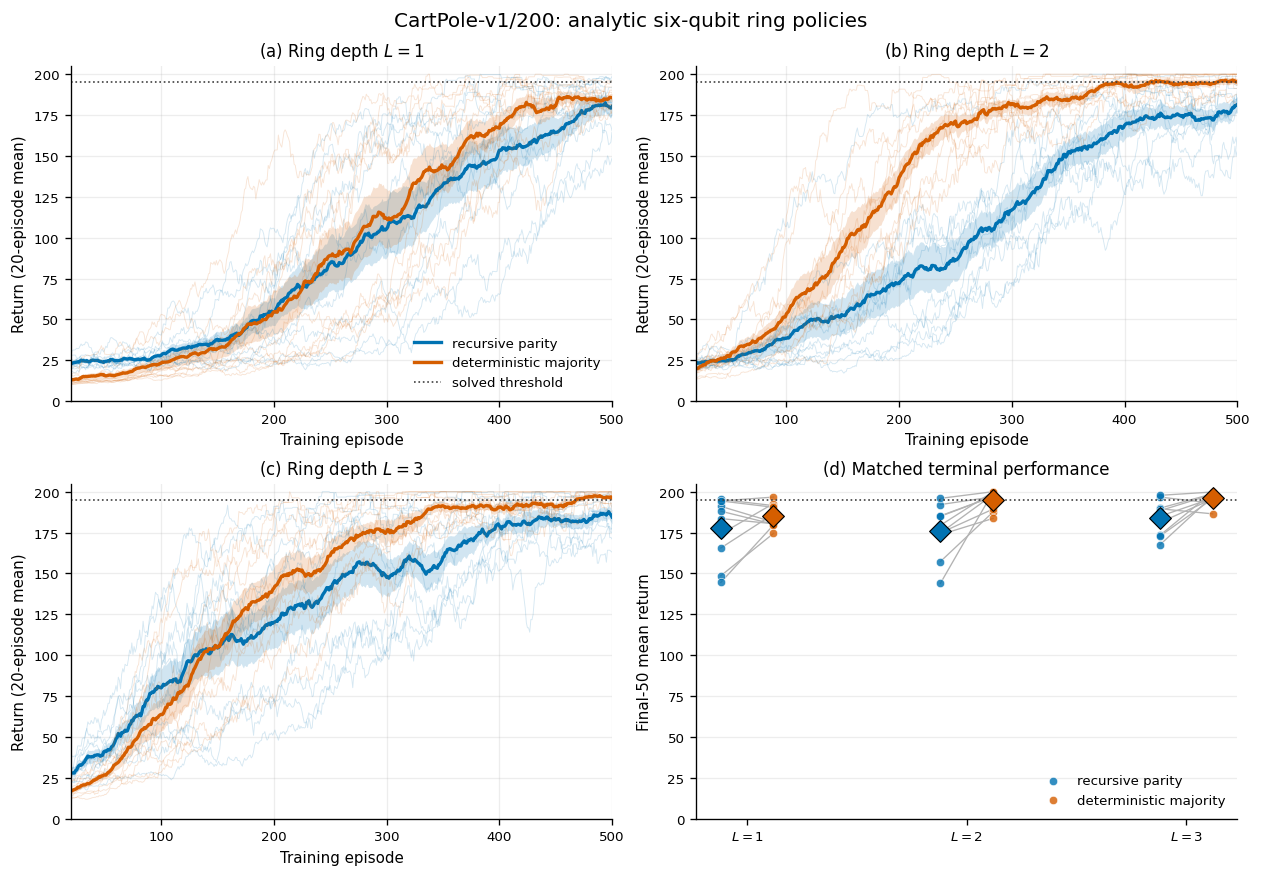

Saved ./tests/results/cartpole_6q_even_majority_vs_parity/figures/cartpole_6q_even_majority_vs_parity.pdf
Saved ./tests/results/cartpole_6q_even_majority_vs_parity/figures/cartpole_6q_even_majority_vs_parity.png


In [9]:
COLORS = {"parity": "#0072B2", "majority": "#D55E00"}
LABELS = {"parity": "recursive parity", "majority": "deterministic majority"}
fig, axes = plt.subplots(2, 2, figsize=(10.4, 7.2), constrained_layout=True)

panel_labels = {1: "(a)", 2: "(b)", 3: "(c)"}
for axis, depth in zip(axes.flat[:3], DEPTHS):
    for policy in ("parity", "majority"):
        matrix = np.stack([
            episode_returns[
                (episode_returns.depth == depth) &
                (episode_returns.policy == policy) &
                (episode_returns.seed == seed)
            ].sort_values("episode")["return"].to_numpy()
            for seed in SEEDS
        ])
        smooth = np.stack([
            np.convolve(run, np.ones(SMOOTHING_WINDOW) / SMOOTHING_WINDOW, mode="valid")
            for run in matrix
        ])
        episodes = np.arange(SMOOTHING_WINDOW, N_EPISODES + 1)
        for run in smooth:
            axis.plot(episodes, run, color=COLORS[policy], lw=0.55, alpha=0.16)
        mean = smooth.mean(axis=0)
        sem = smooth.std(axis=0, ddof=1) / math.sqrt(len(SEEDS))
        axis.plot(episodes, mean, color=COLORS[policy], lw=2.0, label=LABELS[policy])
        axis.fill_between(episodes, np.clip(mean - sem, 0, 200),
                          np.clip(mean + sem, 0, 200),
                          color=COLORS[policy], alpha=0.18, linewidth=0)
    axis.axhline(SOLVED_THRESHOLD, color="0.25", ls=":", lw=1.0,
                 label="solved threshold" if depth == 1 else None)
    axis.set_title(f"{panel_labels[depth]} Ring depth $L={depth}$")
    axis.set_xlim(SMOOTHING_WINDOW, N_EPISODES)
    axis.set_ylim(0, 205)
    axis.set_xlabel("Training episode")
    axis.set_ylabel(f"Return ({SMOOTHING_WINDOW}-episode mean)")
    axis.grid(alpha=0.22)
axes.flat[0].legend(frameon=False, loc="lower right")

axis = axes.flat[3]
x_base = np.arange(len(DEPTHS), dtype=float)
offsets = {"parity": -0.12, "majority": 0.12}
for depth_index, depth in enumerate(DEPTHS):
    subset = run_summary[run_summary.depth == depth].pivot(
        index="seed", columns="policy", values="final_50"
    ).loc[list(SEEDS)]
    for seed in SEEDS:
        axis.plot([x_base[depth_index] + offsets["parity"],
                   x_base[depth_index] + offsets["majority"]],
                  [subset.loc[seed, "parity"], subset.loc[seed, "majority"]],
                  color="0.70", lw=0.8, zorder=1)
    for policy in ("parity", "majority"):
        values = subset[policy].to_numpy()
        axis.scatter(np.full(len(values), x_base[depth_index] + offsets[policy]),
                     values, s=25, color=COLORS[policy], alpha=0.80,
                     edgecolor="white", linewidth=0.4, zorder=2,
                     label=LABELS[policy] if depth_index == 0 else None)
        axis.scatter(x_base[depth_index] + offsets[policy], values.mean(),
                     s=85, marker="D", color=COLORS[policy],
                     edgecolor="black", linewidth=0.7, zorder=3)
axis.axhline(SOLVED_THRESHOLD, color="0.25", ls=":", lw=1.0)
axis.set_xticks(x_base, [f"$L={depth}$" for depth in DEPTHS])
axis.set_ylim(0, 205)
axis.set_ylabel("Final-50 mean return")
axis.set_title("(d) Matched terminal performance")
axis.grid(axis="y", alpha=0.22)
axis.legend(frameon=False, loc="lower right")

fig.suptitle("CartPole-v1/200: analytic six-qubit ring policies", fontsize=12)
fig.savefig(FIGURE_PDF, bbox_inches="tight")
fig.savefig(FIGURE_PNG, dpi=300, bbox_inches="tight")
plt.show()
print("Saved", FIGURE_PDF)
print("Saved", FIGURE_PNG)

## Reproducibility metadata and final checks

The final cell records software versions and checks that all 60 runs, 30,000 episode returns, matched hashes, result tables, and figure files are complete.

In [10]:
def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


metadata = {
    "experiment": "analytic six-qubit ring majority versus parity on CartPole-v1/200",
    "n_qubits": N_QUBITS, "n_actions": N_ACTIONS,
    "depths": list(DEPTHS), "seeds": list(SEEDS),
    "n_episodes": N_EPISODES, "max_steps": MAX_STEPS,
    "final_window": FINAL_WINDOW, "smoothing_window": SMOOTHING_WINDOW,
    "solved_threshold": SOLVED_THRESHOLD, "solved_window": SOLVED_WINDOW,
    "ring_edges": [list(edge) for edge in RING_EDGES],
    "majority_rule": "action 0 iff Hamming weight <= 3; action 1 iff weight >= 4",
    "basis_bin_counts": {"majority": [42, 22], "parity": [32, 32]},
    "execution": "exact analytic statevector, shots=None, reverse-mode autodiff",
    "native_validation": validation.to_dict(orient="records"),
    "training": TRAINING, "n_jobs": N_JOBS,
    "checkpoint_replay_wall_seconds": production_seconds,
    "recorded_training_seconds_sum": float(run_summary.runtime_seconds.sum()),
    "recorded_training_seconds_mean": float(run_summary.runtime_seconds.mean()),
    "python": sys.version, "platform": platform.platform(),
    "versions": {name: package_version(name) for name in
                 ("qasp", "pennylane", "pennylane-lightning", "torch",
                  "gymnasium", "numpy", "pandas", "matplotlib", "joblib")},
    "files": {
        "episode_returns_csv": str(EPISODES_CSV),
        "run_summary_csv": str(RUN_SUMMARY_CSV),
        "statistical_summary_csv": str(STATISTICS_CSV),
        "figure_pdf": str(FIGURE_PDF), "figure_png": str(FIGURE_PNG),
    },
}
METADATA_JSON.write_text(json.dumps(metadata, indent=2, allow_nan=True) + "\n")

assert len(run_summary) == 60
assert len(episode_returns) == 30000
assert run_summary.groupby(["depth", "seed"]).size().eq(2).all()
assert run_summary.groupby(["depth", "seed"]).initial_parameter_sha256.nunique().eq(1).all()
assert set(run_summary.policy) == {"parity", "majority"}
assert all(path.exists() and path.stat().st_size > 0 for path in
           (EPISODES_CSV, RUN_SUMMARY_CSV, STATISTICS_CSV,
            METADATA_JSON, FIGURE_PDF, FIGURE_PNG))
print("All final checks passed.")
print("Runs:", len(run_summary), "Episode rows:", len(episode_returns))
display(run_summary[["depth", "policy", "seed", "final_50",
                     "strict_solved_episode", "runtime_seconds"]].round(3))

All final checks passed.
Runs: 60 Episode rows: 30000


,depth,policy,seed,final_50,strict_solved_episode,runtime_seconds
1,1,majority,3,174.46,NaN,74.754
0,1,parity,3,148.56,NaN,60.594
3,1,majority,7,186.36,NaN,139.140
2,1,parity,7,165.54,NaN,88.379
5,1,majority,11,196.70,432.0,149.476
4,1,parity,11,194.34,NaN,95.746
7,1,majority,23,192.74,NaN,86.397
6,1,parity,23,174.12,NaN,96.255
9,1,majority,37,191.48,NaN,103.654
8,1,parity,37,195.28,NaN,146.991
